In [2]:
import supervision as sv

IMAGE_DIR_PATH = "../dataset/01.office-1/A_office-gray_light-1-flat"

# Load the image
image_path = sv.list_files_with_extensions(
    IMAGE_DIR_PATH, [".jpg", ".jpeg", ".png", ".JPG"])

print(f"Found {len(image_path)} images in {IMAGE_DIR_PATH}")

Found 121 images in ../dataset/01.office-1/A_office-gray_light-1-flat


In [3]:
SAMPLE_SIZE = 16
SAMPLE_GRID = (4, 4)  # (rows, cols)
SAMPLE_PLOT_SIZE = (12, 10)  # (width, height)

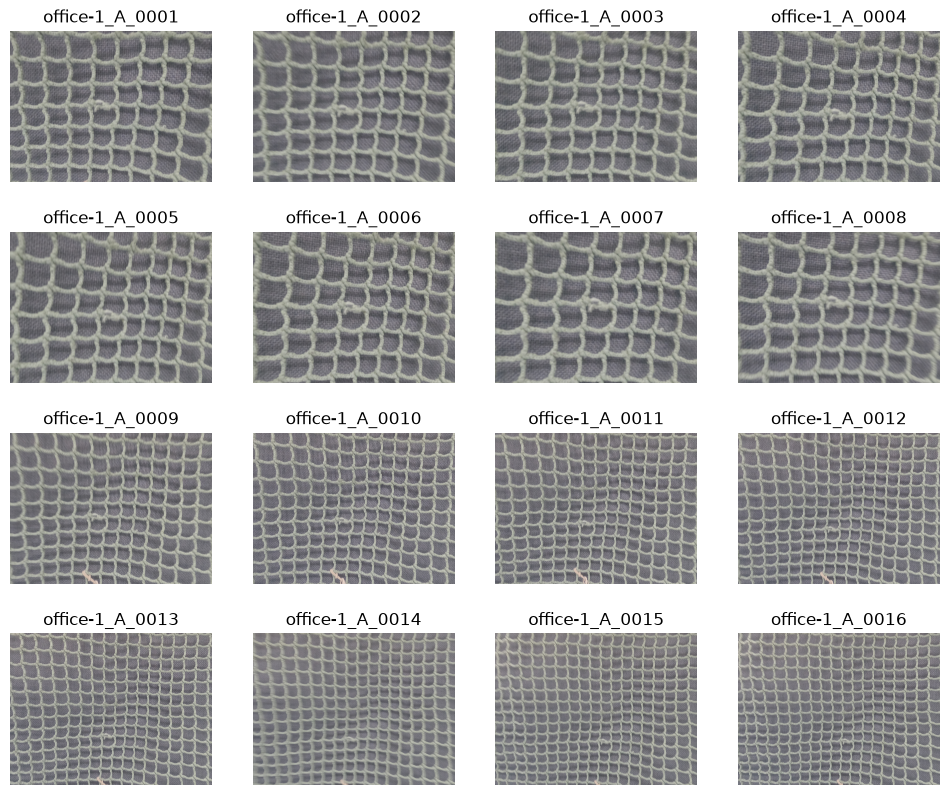

In [4]:
import cv2

titles = [
    image_path.stem
    for image_path in image_path[:SAMPLE_SIZE]
]

images = [
    cv2.imread(str(image_path))
    for image_path in image_path[:SAMPLE_SIZE]
]

sv.plot_images_grid(
    images=images,
    titles=titles,
    grid_size=SAMPLE_GRID,
    size=SAMPLE_PLOT_SIZE
)

# Autolabel

In [12]:
from autodistill.detection import CaptionOntology

# ontology = CaptionOntology({
#     "tear or hole in fishing net mesh": "hole",
#     "frayed or worn rope fibers on fishing net": "frayed",
#     "broken or snapped twine strand in fishing net": "broken_twine",
# })

ontology = CaptionOntology({
    "snag": "damage",
    "loose thread": "damage",
    "hole": "damage",
    "broken strand": "damage",
})


In [13]:
from autodistill_grounded_sam import GroundedSAM

OUTPUT_DIR_PATH = "../output"

base_model = GroundedSAM(ontology=ontology)
dataset = base_model.label(
    input_folder=IMAGE_DIR_PATH,
    extension=".JPG",
    output_folder=OUTPUT_DIR_PATH,
)


trying to load grounding dino directly
final text_encoder_type: bert-base-uncased


Labeling ../dataset/01.office-1/A_office-gray_light-1-flat\office-1_A_0001.JPG:   0%|          | 0/121 [00:00<?, ?it/s]The `device` argument is deprecated and will be removed in v5 of Transformers.
torch.utils.checkpoint: the use_reentrant parameter should be passed explicitly. Starting in PyTorch 2.9, calling checkpoint without use_reentrant will raise an exception. use_reentrant=False is recommended, but if you need to preserve the current default behavior, you can pass use_reentrant=True. Refer to docs for more details on the differences between the two variants.
None of the inputs have requires_grad=True. Gradients will be None
`torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
Labeling ../dataset/01.office-1/A_office-gray_light-1-flat\office-1_A_0121.JPG: 100%|██████████| 121/121 [02:56<00:00,  1.46s/it]


Labeled dataset created - ready for distillation.


## Display annotated images

In [6]:
ANNOTATION_DIR_PATH = "../output/annotations"
ANNOTATED_IMAGES_DIR_PATH = "../output/images"
DATA_YAML_PATH = "../output/data.yaml"

In [7]:
dataset = sv.DetectionDataset.from_yolo(
    images_directory_path=ANNOTATED_IMAGES_DIR_PATH,
    annotations_directory_path=ANNOTATION_DIR_PATH,
    data_yaml_path=DATA_YAML_PATH
)

len(dataset)

121

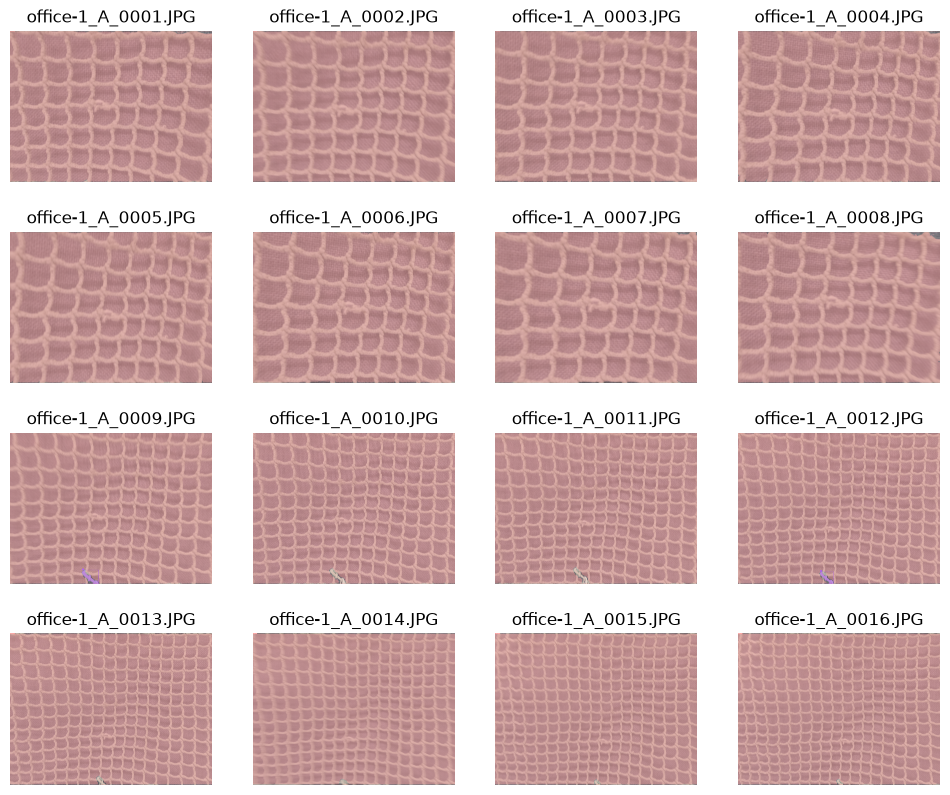

In [9]:
from pathlib import Path

mask_annotator = sv.MaskAnnotator()
box_annotator = sv.BoxAnnotator()
label_annotator = sv.LabelAnnotator()

images = []
image_names = []
for i, (image_path, image, annotation) in enumerate(dataset):
    if i == SAMPLE_SIZE:
        break
    annotated_image = image.copy()
    annotated_image = mask_annotator.annotate(
        scene=annotated_image, detections=annotation)
    annotated_image = box_annotator.annotate(
        scene=annotated_image, detections=annotation)
    annotated_image = label_annotator.annotate(
        scene=annotated_image, detections=annotation)

    image_names.append(Path(image_path).name)
    images.append(annotated_image)

sv.plot_images_grid(
    images=images,
    titles=image_names,
    grid_size=SAMPLE_GRID,
    size=SAMPLE_PLOT_SIZE)

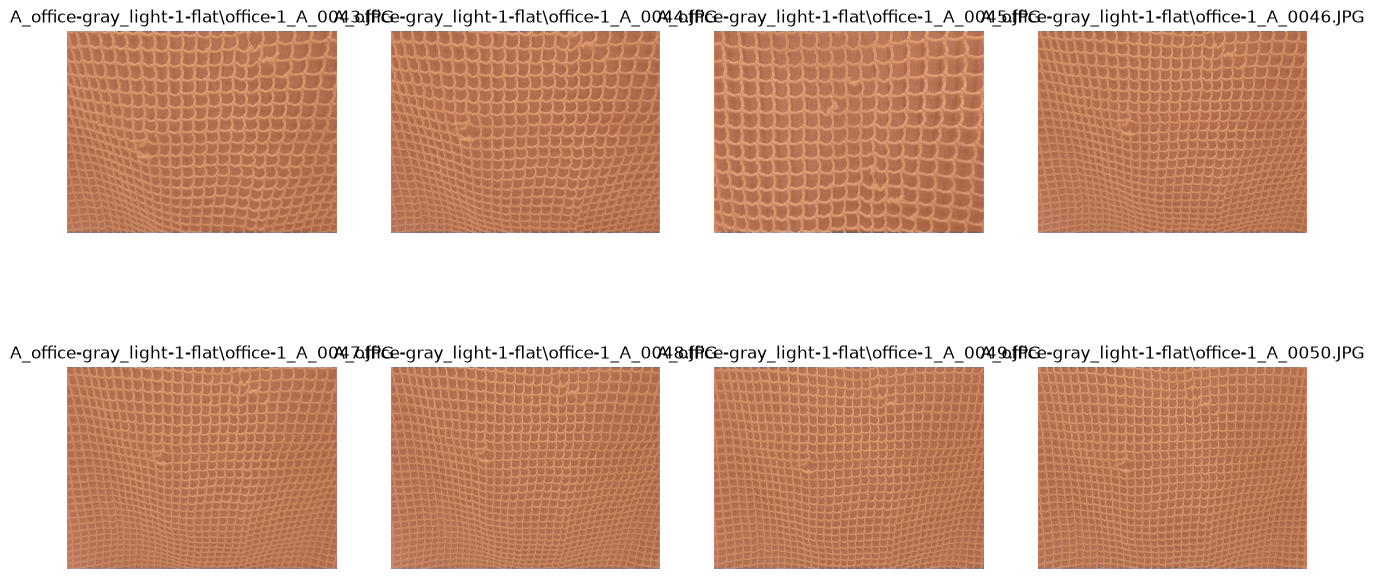

In [14]:
# 2. Set up annotators (compatible with modern supervision versions)
box_annotator = sv.BoxAnnotator()
mask_annotator = sv.MaskAnnotator()
label_annotator = sv.LabelAnnotator()

annotated_images = []
titles = []

# 3. Annotate the first 8 images in the dataset
for image_path, image, annotations in list(dataset)[42:50]:
  labels = [
      f"{dataset.classes[class_id]} {confidence:0.2f}"
      if confidence
      else dataset.classes[class_id]
      for class_id, confidence in zip(
          annotations.class_id,
          annotations.confidence
          if annotations.confidence is not None
          else [None] * len(annotations),
      )
  ]

  annotated_frame = image.copy()

  # Draw masks if using a segmentation model (e.g., GroundedSAM)
  if annotations.mask is not None:
    annotated_frame = mask_annotator.annotate(
        scene=annotated_frame, detections=annotations
    )

  # Draw bounding boxes and labels
  annotated_frame = box_annotator.annotate(
      scene=annotated_frame, detections=annotations
  )
  annotated_frame = label_annotator.annotate(
      scene=annotated_frame, detections=annotations, labels=labels
  )

  annotated_images.append(annotated_frame)
  titles.append(image_path.split("/")[-1])

# 4. Display in a grid
sv.plot_images_grid(
    images=annotated_images, grid_size=(2, 4), titles=titles, size=(16, 8)
)

trying to load grounding dino directly
final text_encoder_type: bert-base-uncased


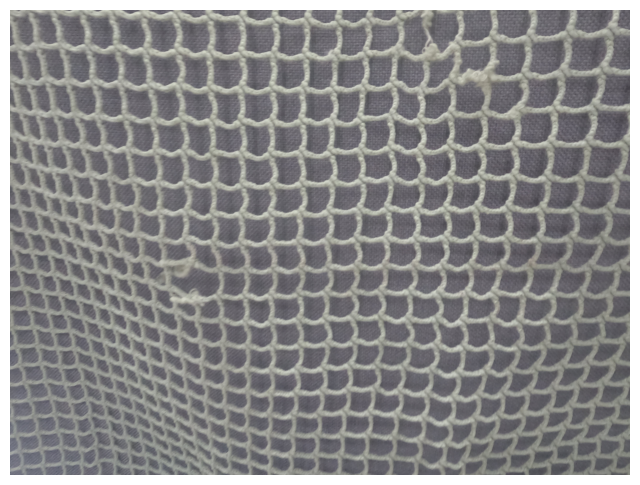

In [20]:
from autodistill.detection import CaptionOntology
from autodistill_grounded_sam import GroundedSAM
import supervision as sv

# 1. Define prompts focused ONLY on the defect (avoid words like "net" or "mesh")
ontology = CaptionOntology({
    "snag net": "damage",
    "loose thread of net": "damage",
    "broken thread": "damage",
    "hole net": "damage",
})

# 2. Initialize GroundedSAM with lower thresholds to catch subtle anomalies
base_model = GroundedSAM(
    ontology=ontology,
    # box_threshold=0.30,  # Default is usually 0.35; lower catches smaller/fainter boxes
    # text_threshold=0.30,  # Default is usually 0.25; lower allows looser text matching
)

# 3. Label a single image or folder
# Note: Use base_model.predict() to test thresholds quickly on 1 image before labeling a whole folder
image_path = f"{IMAGE_DIR_PATH}/office-1_A_0043.JPG"
detections = base_model.predict(image_path)

# 4. Filter out oversized masks/boxes (e.g., anything covering > 25% of the image)
import cv2

image = cv2.imread(image_path)
image_area = image.shape[0] * image.shape[1]
detections = detections[detections.area < (image_area * 0.5)]

# 5. Annotate and display the filtered result
mask_annotator = sv.MaskAnnotator()
box_annotator = sv.BoxAnnotator()
label_annotator = sv.LabelAnnotator()

labels = [
    f"{ontology.classes()[class_id]} {conf:.2f}"
    for class_id, conf in zip(detections.class_id, detections.confidence)
]

annotated_image = image.copy()
annotated_image = mask_annotator.annotate(
    scene=annotated_image, detections=detections
)
annotated_image = box_annotator.annotate(
    scene=annotated_image, detections=detections
)
annotated_image = label_annotator.annotate(
    scene=annotated_image, detections=detections, labels=labels
)

sv.plot_image(image=annotated_image, size=(8, 8))


In [4]:
from sam2 import build_sam
import sam2.build_sam

_original_build_sam2 = sam2.build_sam.build_sam2


def _patched_build_sam2(config_file, ckpt_path=None, *args, **kwargs):
  if config_file == "sam2_hiera_b+.yaml":
    config_file = "configs/sam2/sam2_hiera_b+.yaml"
  return _original_build_sam2(config_file, ckpt_path, *args, **kwargs)


sam2.build_sam.build_sam2 = _patched_build_sam2

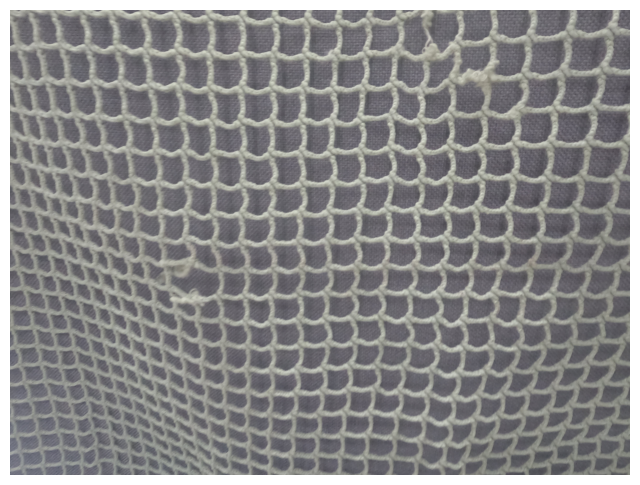

In [6]:
from autodistill.detection import CaptionOntology
from autodistill_grounded_sam_2 import GroundedSAM2
import cv2
import supervision as sv

# 1. Define descriptive ontology mapping to target specific anomalies
ontology = CaptionOntology({
    "tangled thread": "damage",
    "broken yarn": "damage",
    "fabric snag": "damage",
    "loose fiber": "damage",
    "frayed thread": "damage",
    "irregular knot": "damage",
})

# 2. Initialize GroundedSAM2 model
base_model = GroundedSAM2(ontology=ontology)

# 3. Predict on a test image and filter out large background masks (>25% area)
image_path = f"{IMAGE_DIR_PATH}/office-1_A_0043.JPG"
detections = base_model.predict(image_path)
image = cv2.imread(image_path)
image_area = image.shape[0] * image.shape[1]
detections = detections[detections.area < (image_area * 0.25)]

# 4. Annotate and visualize results using Supervision
mask_annotator = sv.MaskAnnotator()
box_annotator = sv.BoxAnnotator()
label_annotator = sv.LabelAnnotator()

classes = base_model.ontology.classes()
confidences = (
    detections.confidence
    if detections.confidence is not None
    else [None] * len(detections)
)

labels = [
    f"{classes[class_id]} {conf:.2f}" if conf is not None else classes[class_id]
    for class_id, conf in zip(detections.class_id, confidences)
]

annotated_image = image.copy()
if detections.mask is not None:
    annotated_image = mask_annotator.annotate(scene=annotated_image, detections=detections)
annotated_image = box_annotator.annotate(scene=annotated_image, detections=detections)
annotated_image = label_annotator.annotate(scene=annotated_image, detections=detections, labels=labels)

sv.plot_image(image=annotated_image, size=(8, 8))


# Few shot
Use annotated images to label others

In [ ]:
import os
from pathlib import Path
import shutil
import urllib.request

PROJECT_DIR = Path.cwd().resolve()

# 1. Exact path expected by autodistill-seggpt
cache_dir = Path(os.path.expanduser("~")) / ".cache" / "autodistill"
target_models_dir = cache_dir / "Painter" / "SegGPT" / "SegGPT_inference" / "models"
target_models_dir.mkdir(parents=True, exist_ok=True)
target_ckpt = target_models_dir / "seggpt_vit_large.pth"

# 2. Check if we already downloaded it into the old 'seggpt_models' folder and move it
old_ckpt = cache_dir / "seggpt_models" / "seggpt_vit_large.pth"

if not target_ckpt.exists():
    if old_ckpt.exists():
        print(f"Moving existing checkpoint to {target_ckpt}...")
        shutil.move(str(old_ckpt), str(target_ckpt))
    else:
        model_url = "https://huggingface.co"
        print(f"Downloading SegGPT weights to {target_ckpt}...")
        urllib.request.urlretrieve(model_url, str(target_ckpt))

print("Checkpoint ready:", target_ckpt.exists(), "| Size (MB):", round(target_ckpt.stat().st_size / 1e6, 1))

Download complete!


## Resize images

In [1]:
import cv2
from cv2.typing import MatLike 

def resize_image(
    image_path: str, 
    max_size: int = 1024
) -> tuple[MatLike, float]:
    # Load the image
    image = cv2.imread(image_path)
    original_height, original_width = image.shape[:2]

    # Calculate the scaling factor
    scale = min(max_size / max(original_width, original_height), 1.0)  # Ensure we don't upscale

    # Calculate the new dimensions
    new_width = int(round(original_width * scale))
    new_height = int(round(original_height * scale))

    if scale < 1.0:
        resized_image = cv2.resize(image, (new_width, new_height), interpolation=cv2.INTER_AREA)
    else:
        # Image size is within the limit; no resizing needed.
        resized_image = image

    return resized_image, scale, new_width, new_height

In [2]:
import supervision as sv
import cv2
import numpy as np

def resize_dataset(
    dataset: sv.DetectionDataset, 
    max_side: int = 1024, 
    max_images: int = 5,
    offset: int = 0
) -> sv.DetectionDataset:
  selected_keys = list(dataset.annotations.keys())[offset:offset + max_images]
  resized_images = {}
  resized_annotations = {}

  for img_path in selected_keys:
    # img = cv2.imread(img_path)
    img, scale, new_w, new_h = resize_image(img_path, max_side)
    
    if img is None:
      continue
    
    ann = dataset.annotations[img_path]

    # orig_h, orig_w = img.shape[:2]

    # scale = min(max_side / max(orig_h, orig_w), 1.0)
    # new_w = int(round(orig_w * scale))
    # new_h = int(round(orig_h * scale))

    if scale < 1.0:
      # img = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)
      new_xyxy = ann.xyxy * scale

      new_mask = None
      if ann.mask is not None and len(ann.mask) > 0:
        resized_masks = []
        for m in ann.mask:
          m_resized = cv2.resize(
              m.astype(np.uint8), (new_w, new_h), interpolation=cv2.INTER_NEAREST
          )
          resized_masks.append(m_resized.astype(bool))
        new_mask = np.array(resized_masks)

      new_ann = sv.Detections(
          xyxy=new_xyxy,
          mask=new_mask,
          class_id=ann.class_id.copy() if ann.class_id is not None else None,
          confidence=(
              ann.confidence.copy() if ann.confidence is not None else None
          ),
      )
    else:
      new_ann = ann

    resized_images[img_path] = img
    resized_annotations[img_path] = new_ann

  resized_dataset = sv.DetectionDataset(
      classes=dataset.classes,
      images=resized_images,
      annotations=resized_annotations,
  )
  resized_dataset.images = resized_images

  return resized_dataset

c:\Users\wapra1274\AppData\Local\miniconda3\envs\wap-autolabel\Lib\site-packages\supervision\annotators\utils.py:192: FutureWarning: `template_mgs` is deprecated since `v0.12` (renamed to `message_template`); use `message_template` instead. Will be removed in `v1.0`.
  @deprecated(  # type: ignore[untyped-decorator]
c:\Users\wapra1274\AppData\Local\miniconda3\envs\wap-autolabel\Lib\site-packages\supervision\annotators\utils.py:280: FutureWarning: `template_mgs` is deprecated since `v0.12` (renamed to `message_template`); use `message_template` instead. Will be removed in `v1.0`.
  @deprecated(  # type: ignore[untyped-decorator]
c:\Users\wapra1274\AppData\Local\miniconda3\envs\wap-autolabel\Lib\site-packages\supervision\annotators\utils.py:325: FutureWarning: `template_mgs` is deprecated since `v0.12` (renamed to `message_template`); use `message_template` instead. Will be removed in `v1.0`.
  @deprecated(  # type: ignore[untyped-decorator]
c:\Users\wapra1274\AppData\Local\miniconda3\en

In [ ]:
import gc
from pathlib import Path
from autodistill_seggpt import FewShotOntology, SegGPT
import cv2
import supervision as sv
import yaml
import torch

gc.collect()
torch.cuda.empty_cache()

# Patch torch.load to ensure weights_only=False for SegGPT compatibility
if not getattr(torch.load, "_is_patched", False):
  _original_torch_load = torch.load

  def _patched_torch_load(*args, **kwargs):
    if "weights_only" not in kwargs:
      kwargs["weights_only"] = False
    return _original_torch_load(*args, **kwargs)

  _patched_torch_load._is_patched = True
  torch.load = _patched_torch_load

if not hasattr(sv.detection.utils, "mask_to_xyxy"):
  sv.detection.utils.mask_to_xyxy = sv.mask_to_xyxy

# Patch Detections.__iter__ to yield 5 values for compatibility with autodistill-seggpt
def _legacy_detections_iter(self):
  for i in range(len(self.xyxy)):
    yield (
        self.xyxy[i],
        self.mask[i] if self.mask is not None else None,
        self.confidence[i] if self.confidence is not None else None,
        self.class_id[i] if self.class_id is not None else None,
        self.tracker_id[i] if self.tracker_id is not None else None,
    )


sv.Detections.__iter__ = _legacy_detections_iter

# 1. Define paths to your Label Studio YOLO export
export_dir = Path("../dataset/fewshots")
images_dir = export_dir / "images"
labels_dir = export_dir / "labels"
classes_txt = export_dir / "classes.txt"
data_yaml_path = export_dir / "data.yaml"

# 2. Convert Label Studio's classes.txt into data.yaml required by supervision
with open(classes_txt, "r", encoding="utf-8") as f:
  class_names = [line.strip() for line in f if line.strip()]

data_yaml_content = {"nc": len(class_names), "names": class_names}
with open(data_yaml_path, "w", encoding="utf-8") as f:
  yaml.safe_dump(data_yaml_content, f, sort_keys=False)

# 3. Load your few-shot examples into a supervision DetectionDataset
# Note: Your Label Studio export must use Polygon labels (YOLO segmentation format)
full_dataset = sv.DetectionDataset.from_yolo(
    images_directory_path=str(images_dir),
    annotations_directory_path=str(labels_dir),
    data_yaml_path=str(data_yaml_path),
)

if not hasattr(full_dataset, "images"):
  full_dataset.images = {
      image_path: image for image_path, image, _ in full_dataset
  }


# 2. Keep ONLY 2-3 best reference images (prevents quadratic O(N^2) attention explosion)
MAX_REF_IMAGES = 70
OFFSET = 10
selected_keys = list(full_dataset.annotations.keys())[OFFSET:OFFSET + MAX_REF_IMAGES]

# 3. Load the selected images and annotations directly with matching keys
selected_images = {k: cv2.imread(k) for k in selected_keys}
selected_annotations = {k: full_dataset.annotations[k] for k in selected_keys}

# few_shot_dataset = sv.DetectionDataset(
#     classes=full_dataset.classes,
#     images=selected_images,
#     annotations=selected_annotations,
# )

# # Explicitly attach .images for compatibility with autodistill-seggpt
# few_shot_dataset.images = selected_images

few_shot_dataset = resize_dataset(
    dataset=full_dataset,
    max_side=1024,  # 5184x3888 -> 1024x768
    max_images=MAX_REF_IMAGES,  
    offset=OFFSET
)

print(
    f"Loaded {len(few_shot_dataset)} few-shot examples with classes:"
    f" {few_shot_dataset.classes}"
)

# 4. Initialize SegGPT with FewShotOntology
ontology = FewShotOntology(few_shot_dataset)
base_model = SegGPT(ontology=ontology)

# 5. Test on a single unseen image
# IMAGE_DIR_PATH = "../dataset/01.office-1/A_office-gray_light-1-gopro"
# test_image_path = f"{IMAGE_DIR_PATH}/office-1_A_0232.JPG" #office-1_A_0232 
# test_image_path = "../dataset/fewshots/images/2563ad32__G0171968.JPG"
test_image_path = "../dataset\\01.office-1\\A_office-gray_light-1-gopro\\office-1_A_0193.JPG"

test_img, scale, new_w, new_h = resize_image(test_image_path)

with torch.inference_mode(), torch.amp.autocast("cuda", dtype=torch.float16):
  # detections = base_model.predict(test_image_path)
  detections = base_model.predict(test_img)

# Optional: Filter out oversized masks (>25% of image area) just in case
# image = cv2.imread(test_image_path)
# image_area = image.shape[0] * image.shape[1]
image_area = test_img.shape[0] * test_img.shape[1]
detections = detections[detections.area < (image_area * 0.25)]

# 6. Annotate and display the prediction
# mask_annotator = sv.MaskAnnotator()
color_annotator = sv.ColorAnnotator(opacity=0.25)
box_annotator = sv.BoxAnnotator(thickness=2)
label_annotator = sv.LabelAnnotator()

labels = [
    f"{few_shot_dataset.classes[class_id]}" for class_id in detections.class_id
]

annotated_image = test_img.copy()
# annotated_image = image.copy()
# if detections.mask is not None:
#   annotated_image = mask_annotator.annotate(
#       scene=annotated_image, detections=detections
#   )
annotated_image = color_annotator.annotate(
    scene=annotated_image, detections=detections
)
annotated_image = box_annotator.annotate(
    scene=annotated_image, detections=detections
)
annotated_image = label_annotator.annotate(
    scene=annotated_image, detections=detections, labels=labels
)

sv.plot_image(image=annotated_image, size=(8, 8))

# 7. Once verified, auto-label your full folder of unlabeled images
# base_model.label(
#     input_folder="./unlabeled_images",
#     extension=".jpg",
#     output_folder="./auto_labeled_dataset"
# )


`torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
Importing from timm.models.layers is deprecated, please import via timm.layers
Passing a `Dict[str, np.ndarray]` into `DetectionDataset` is deprecated in `0.30.0` and will be removed in `0.33.0`. Use a list of paths `List[str]` instead.


Loaded 75 few-shot examples with classes: ['damage', 'hole']


OutOfMemoryError: CUDA out of memory. Tried to allocate 21.98 GiB. GPU 0 has a total capacity of 23.99 GiB of which 0 bytes is free. Process 11348 has 17179869184.00 GiB memory in use. Process 4076 has 17179869184.00 GiB memory in use. Process 14584 has 17179869184.00 GiB memory in use. Process 9540 has 17179869184.00 GiB memory in use. Process 2804 has 17179869184.00 GiB memory in use. Process 15596 has 17179869184.00 GiB memory in use. Process 1668 has 17179869184.00 GiB memory in use. Process 1500 has 17179869184.00 GiB memory in use. Process 17180 has 17179869184.00 GiB memory in use. Process 9480 has 17179869184.00 GiB memory in use. Process 11168 has 17179869184.00 GiB memory in use. Process 7008 has 17179869184.00 GiB memory in use. Process 18036 has 17179869184.00 GiB memory in use. Process 14000 has 17179869184.00 GiB memory in use. Process 32564 has 17179869184.00 GiB memory in use. Process 15568 has 17179869184.00 GiB memory in use. Process 19940 has 17179869184.00 GiB memor

In [18]:
# if '71968' in selected_images.keys():
#     print("Found image 71968 in selected_images")
search = "2563ad32__G0171968" #2563ad32__G0171968
found = any(search in str(key) for key in selected_images.keys())
if found:
    print(f"Found image {search} in selected_images with key:")

indices = [i for i, k in enumerate(full_dataset.annotations) if search in k]  # [0, 2]
indices

Found image 2563ad32__G0171968 in selected_images with key:


[21]

In [12]:
for key in selected_images.keys():
    print(key)

..\dataset\fewshots\images\abe1eed9__G0171941.JPG
..\dataset\fewshots\images\afab72c6__G0172036.JPG
..\dataset\fewshots\images\b01fb51c__G0171959.JPG
..\dataset\fewshots\images\b4bc794d__G0171964.JPG
..\dataset\fewshots\images\b4c0c9c5__G0171977.JPG
..\dataset\fewshots\images\bc80e22f__G0171973.JPG
..\dataset\fewshots\images\bce47b8f__G0172048.JPG
..\dataset\fewshots\images\be7cb031__G0172054.JPG
..\dataset\fewshots\images\c30967f2__G0171940.JPG
..\dataset\fewshots\images\c36f29d1__G0171991.JPG
..\dataset\fewshots\images\c4ecfa42__G0171980.JPG
..\dataset\fewshots\images\cbb65311__G0171971.JPG
..\dataset\fewshots\images\cc82a17a__G0172033.JPG
..\dataset\fewshots\images\cd86d937__G0172039.JPG
..\dataset\fewshots\images\cde027f1__G0171952.JPG
..\dataset\fewshots\images\ceee325b__G0172037.JPG
..\dataset\fewshots\images\d1469b02__G0172043.JPG
..\dataset\fewshots\images\d19ba849__G0171967.JPG
..\dataset\fewshots\images\d4f832f0__G0171937.JPG
..\dataset\fewshots\images\d9179fa8__G0171950.JPG


In [5]:
import os
from pathlib import Path

cache_dir = Path(os.path.expanduser("~")) / ".cache" / "autodistill"
cache_dir.mkdir(parents=True, exist_ok=True)
print("Autodistill cache folder:", cache_dir)


Autodistill cache folder: C:\Users\dev\.cache\autodistill


In [3]:
import os

os.getcwd()

'd:\\Andy\\autolabel\\src'

In [11]:
mylist = [i for i in range(50)]
mylist[42:20]

[]